In [1]:
import sys
import torch
import torchvision

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Current runtime is using CPU.")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [4]:
import os
import zipfile

zip_path = "/content/" + next(
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
)

extract_dir = "/content/plantdoc_raw"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully.")
print("Location:", extract_dir)
print("Files:", os.listdir(extract_dir))

Dataset extracted successfully.
Location: /content/plantdoc_raw
Files: ['README.roboflow.txt', 'valid', 'data.yaml', 'test', 'train', 'README.dataset.txt']


In [5]:
import os

for root, dirs, files in os.walk(extract_dir):
    depth = root.replace(extract_dir, "").count(os.sep)

    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/")

plantdoc_raw/
  valid/
    labels/
    images/
  test/
    labels/
    images/
  train/
    labels/
    images/


In [6]:
import yaml

yaml_path = os.path.join(extract_dir, "data.yaml")

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print(data_config)

{'names': ['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf spot', 'Bell_pepper leaf', 'Blueberry leaf', 'Cherry leaf', 'Corn Gray leaf spot', 'Corn leaf blight', 'Corn rust leaf', 'Peach leaf', 'Potato leaf early blight', 'Potato leaf late blight', 'Potato leaf', 'Raspberry leaf', 'Soyabean leaf', 'Soybean leaf', 'Squash Powdery mildew leaf', 'Strawberry leaf', 'Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato leaf', 'Tomato mold leaf', 'Tomato two spotted spider mites leaf', 'grape leaf black rot', 'grape leaf'], 'nc': 30, 'roboflow': {'license': 'CC BY 4.0', 'project': 'plantdoc', 'url': 'https://universe.roboflow.com/joseph-nelson/plantdoc/dataset/1', 'version': 1, 'workspace': 'joseph-nelson'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


#Prepare classification crops


In [7]:
from pathlib import Path
from PIL import Image
from collections import Counter

root = Path(extract_dir)
crop_root = Path("/content/plantdoc_classification")

class_names = data_config["names"]
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
counts = Counter()
skipped = Counter()

for split in ["train", "valid", "test"]:
    split_dir = root / split
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    label_map = {
        p.relative_to(labels_dir).with_suffix("").as_posix(): p
        for p in labels_dir.rglob("*.txt")
    }

    for img_path in images_dir.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue

        key = img_path.relative_to(images_dir).with_suffix("").as_posix()
        label_path = label_map.get(key)

        if label_path is None:
            skipped["missing_label"] += 1
            continue

        with open(label_path, "r") as f:
            lines = [line.split() for line in f if line.strip()]

        if not lines:
            skipped["empty_label"] += 1
            continue

        try:
            annotations = [
                (int(row[0]), list(map(float, row[1:])))
                for row in lines if len(row) == 5
            ]
        except ValueError:
            skipped["invalid_label"] += 1
            continue

        if not annotations:
            skipped["invalid_label"] += 1
            continue

        class_ids = {a[0] for a in annotations}

        if len(class_ids) != 1:
            skipped["multiple_classes"] += 1
            continue

        class_id = next(iter(class_ids))

        if not 0 <= class_id < len(class_names):
            skipped["unknown_class"] += 1
            continue

        try:
            with Image.open(img_path) as im:
                im = im.convert("RGB")
                w, h = im.size

                for box_id, (_, box) in enumerate(annotations):
                    xc, yc, bw, bh = box

                    if not all(0 <= v <= 1 for v in box):
                        skipped["invalid_box"] += 1
                        continue

                    x1 = max(0, int((xc - bw / 2) * w))
                    y1 = max(0, int((yc - bh / 2) * h))
                    x2 = min(w, int((xc + bw / 2) * w))
                    y2 = min(h, int((yc + bh / 2) * h))

                    if x2 <= x1 or y2 <= y1:
                        skipped["invalid_box"] += 1
                        continue

                    crop = im.crop((x1, y1, x2, y2))

                    if crop.width < 16 or crop.height < 16:
                        skipped["small_crop"] += 1
                        continue

                    class_folder = crop_root / split / str(class_id)
                    class_folder.mkdir(parents=True, exist_ok=True)

                    out_path = class_folder / f"{img_path.stem}_{box_id}.jpg"
                    crop.save(out_path, quality=95)
                    counts[(split, class_id)] += 1

        except Exception:
            skipped["image_error"] += 1

print("Crop preparation complete.")
print("Crops per split:", {
    split: sum(v for (s, _), v in counts.items() if s == split)
    for split in ["train", "valid", "test"]
})
print("Skipped:", dict(skipped))
print("Output:", crop_root)

Crop preparation complete.
Crops per split: {'train': 6913, 'valid': 1245, 'test': 454}
Skipped: {'small_crop': 68, 'multiple_classes': 19, 'empty_label': 11}
Output: /content/plantdoc_classification


In [8]:
from pathlib import Path

crop_root = Path("/content/plantdoc_classification")

for split in ["train", "valid", "test"]:
    split_dir = crop_root / split
    print(f"\n{split.upper()}")

    total = 0

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        count = sum(
            1 for p in class_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

        total += count
        print(f"Class {class_dir.name}: {count} images")

    print("Total:", total)


TRAIN
Class 0: 133 images
Class 1: 193 images
Class 10: 509 images
Class 12: 250 images
Class 13: 192 images
Class 14: 410 images
Class 15: 211 images
Class 16: 15 images
Class 17: 204 images
Class 18: 360 images
Class 19: 136 images
Class 2: 145 images
Class 20: 344 images
Class 21: 283 images
Class 22: 199 images
Class 23: 164 images
Class 24: 172 images
Class 25: 646 images
Class 26: 236 images
Class 28: 188 images
Class 29: 111 images
Class 3: 254 images
Class 4: 215 images
Class 5: 682 images
Class 6: 187 images
Class 7: 67 images
Class 8: 303 images
Class 9: 104 images
Total: 6913

VALID
Class 0: 24 images
Class 1: 44 images
Class 10: 59 images
Class 12: 40 images
Class 13: 41 images
Class 14: 129 images
Class 15: 35 images
Class 17: 44 images
Class 18: 83 images
Class 19: 15 images
Class 2: 22 images
Class 20: 55 images
Class 21: 55 images
Class 22: 48 images
Class 23: 39 images
Class 24: 51 images
Class 25: 61 images
Class 26: 42 images
Class 28: 17 images
Class 29: 14 images


In [9]:
from pathlib import Path
import shutil

source_root = Path("/content/plantdoc_classification")
filtered_root = Path("/content/plantdoc_classification_filtered")

splits = ["train", "valid", "test"]

# Find classes that contain images in every split
class_sets = []

for split in splits:
    split_dir = source_root / split
    available = {
        folder.name
        for folder in split_dir.iterdir()
        if folder.is_dir() and any(
            file.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
            for file in folder.iterdir()
        )
    }
    class_sets.append(available)

common_classes = sorted(
    set.intersection(*class_sets),
    key=int
)

print("Common classes:", common_classes)
print("Number of classes:", len(common_classes))

# Create the filtered dataset
if filtered_root.exists():
    shutil.rmtree(filtered_root)

for split in splits:
    for class_id in common_classes:
        src = source_root / split / class_id
        dst = filtered_root / split / class_id
        dst.mkdir(parents=True, exist_ok=True)

        for image_path in src.iterdir():
            if image_path.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".webp"
            }:
                shutil.copy2(image_path, dst / image_path.name)

print("Filtered dataset created:", filtered_root)

Common classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '12', '13', '14', '15', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '28', '29']
Number of classes: 27
Filtered dataset created: /content/plantdoc_classification_filtered


In [10]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

filtered_root = Path("/content/plantdoc_classification_filtered")

image_size = 224
batch_size = 32

# ImageNet normalization
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and test transformations
eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load datasets
train_dataset = datasets.ImageFolder(
    str(filtered_root / "train"),
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    str(filtered_root / "valid"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    str(filtered_root / "test"),
    transform=eval_transform
)

# Confirm that all splits use the same class mapping
assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

# Create data loaders
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Data loaders created successfully.")
print("Number of classes:", len(train_dataset.classes))
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))
print("Class mapping:", train_dataset.class_to_idx)
print("Device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

Data loaders created successfully.
Number of classes: 27
Training images: 6898
Validation images: 1245
Testing images: 454
Class mapping: {'0': 0, '1': 1, '10': 2, '12': 3, '13': 4, '14': 5, '15': 6, '17': 7, '18': 8, '19': 9, '2': 10, '20': 11, '21': 12, '22': 13, '23': 14, '24': 15, '25': 16, '26': 17, '28': 18, '29': 19, '3': 20, '4': 21, '5': 22, '6': 23, '7': 24, '8': 25, '9': 26}
Device: CUDA GPU


In [11]:
from pathlib import Path

crop_root = Path("/content/plantdoc_classification")

all_class_ids = [str(i) for i in range(len(class_names))]

for split in ["train", "valid", "test"]:
    for class_id in all_class_ids:
        (crop_root / split / class_id).mkdir(
            parents=True, exist_ok=True
        )

print("All class folders are now consistent.")

All class folders are now consistent.


Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])


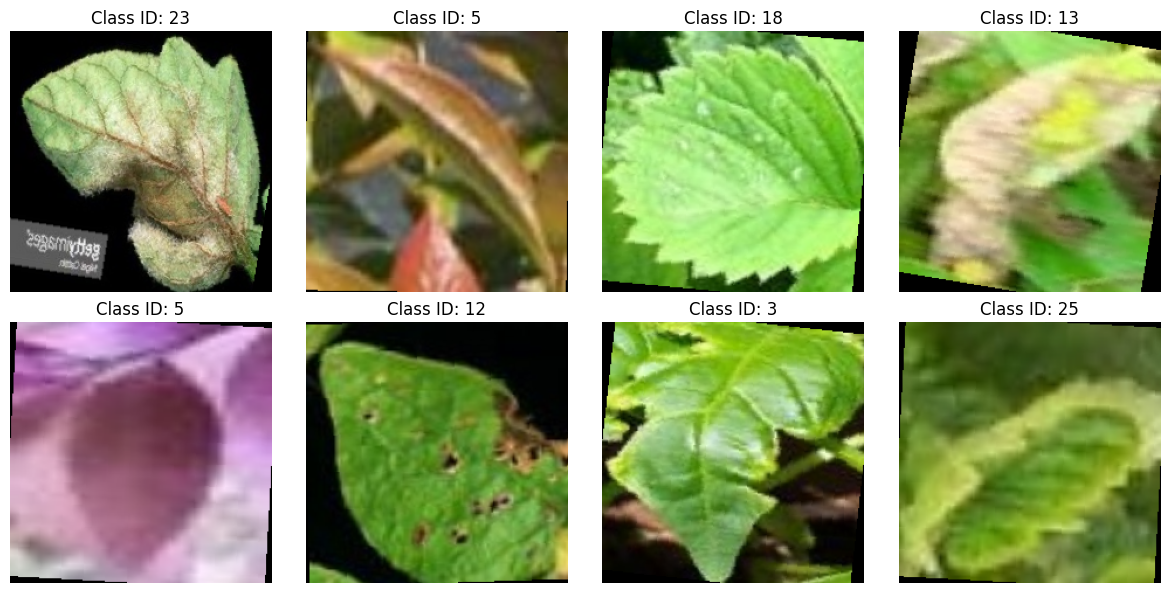

In [12]:
import matplotlib.pyplot as plt

# Get one batch of training images
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

# Display 8 images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0)

    class_id = train_dataset.classes[labels[i].item()]
    ax.imshow(image)
    ax.set_title(f"Class ID: {class_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Build the CNN baseline


In [13]:
import torch
import torch.nn as nn
import torch.optim as optim

# Use the available GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define a simple CNN
class PlantDiseaseCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# Create model, loss function, and optimizer
cnn_model = PlantDiseaseCNN(
    num_classes=len(train_dataset.classes)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("CNN model created successfully.")
print("Device:", device)
print("Number of classes:", len(train_dataset.classes))
print("Trainable parameters:",
      sum(p.numel() for p in cnn_model.parameters() if p.requires_grad))

CNN model created successfully.
Device: cuda
Number of classes: 27
Trainable parameters: 395355


##Train the CNN

In [14]:
import time
import torch

num_epochs = 10
best_val_accuracy = 0.0
cnn_history = []

for epoch in range(num_epochs):
    start_time = time.time()

    # Training phase
    cnn_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation phase
    cnn_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    cnn_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(cnn_model.state_dict(), "/content/best_cnn_model.pth")

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

print(f"\nBest validation accuracy: {best_val_accuracy:.4f}")
print("Best model saved to /content/best_cnn_model.pth")

Epoch [1/10] Train Loss: 3.0606 | Train Acc: 0.1321 | Val Loss: 3.0917 | Val Acc: 0.0755 | Time: 23.1s
Epoch [2/10] Train Loss: 2.8944 | Train Acc: 0.1676 | Val Loss: 2.9960 | Val Acc: 0.1141 | Time: 20.8s
Epoch [3/10] Train Loss: 2.7473 | Train Acc: 0.2025 | Val Loss: 2.8303 | Val Acc: 0.1349 | Time: 20.8s
Epoch [4/10] Train Loss: 2.6670 | Train Acc: 0.2189 | Val Loss: 2.8438 | Val Acc: 0.1454 | Time: 20.7s
Epoch [5/10] Train Loss: 2.6074 | Train Acc: 0.2373 | Val Loss: 2.8450 | Val Acc: 0.1301 | Time: 20.5s
Epoch [6/10] Train Loss: 2.5706 | Train Acc: 0.2479 | Val Loss: 2.8340 | Val Acc: 0.1462 | Time: 20.5s
Epoch [7/10] Train Loss: 2.5229 | Train Acc: 0.2601 | Val Loss: 2.8445 | Val Acc: 0.1414 | Time: 20.7s
Epoch [8/10] Train Loss: 2.4865 | Train Acc: 0.2702 | Val Loss: 2.7949 | Val Acc: 0.1663 | Time: 21.0s
Epoch [9/10] Train Loss: 2.4594 | Train Acc: 0.2796 | Val Loss: 2.7290 | Val Acc: 0.1695 | Time: 20.9s
Epoch [10/10] Train Loss: 2.4187 | Train Acc: 0.2827 | Val Loss: 2.7586 |

#Evaluate the best CNN on the test set

Test Accuracy: 0.1894

Classification Report:
              precision    recall  f1-score   support

           0      0.000     0.000     0.000        13
           1      0.222     0.200     0.211        10
          10      0.000     0.000     0.000        10
          12      0.000     0.000     0.000        17
          13      0.000     0.000     0.000        10
          14      0.200     0.176     0.188        17
          15      0.000     0.000     0.000        20
          17      0.200     0.750     0.316         8
          18      0.246     0.567     0.343        30
          19      0.000     0.000     0.000        19
           2      0.000     0.000     0.000        11
          20      0.219     0.292     0.250        24
          21      0.083     0.148     0.107        27
          22      0.250     0.071     0.111        14
          23      0.500     0.286     0.364        14
          24      1.000     0.083     0.154        36
          25      0.578     0.619  

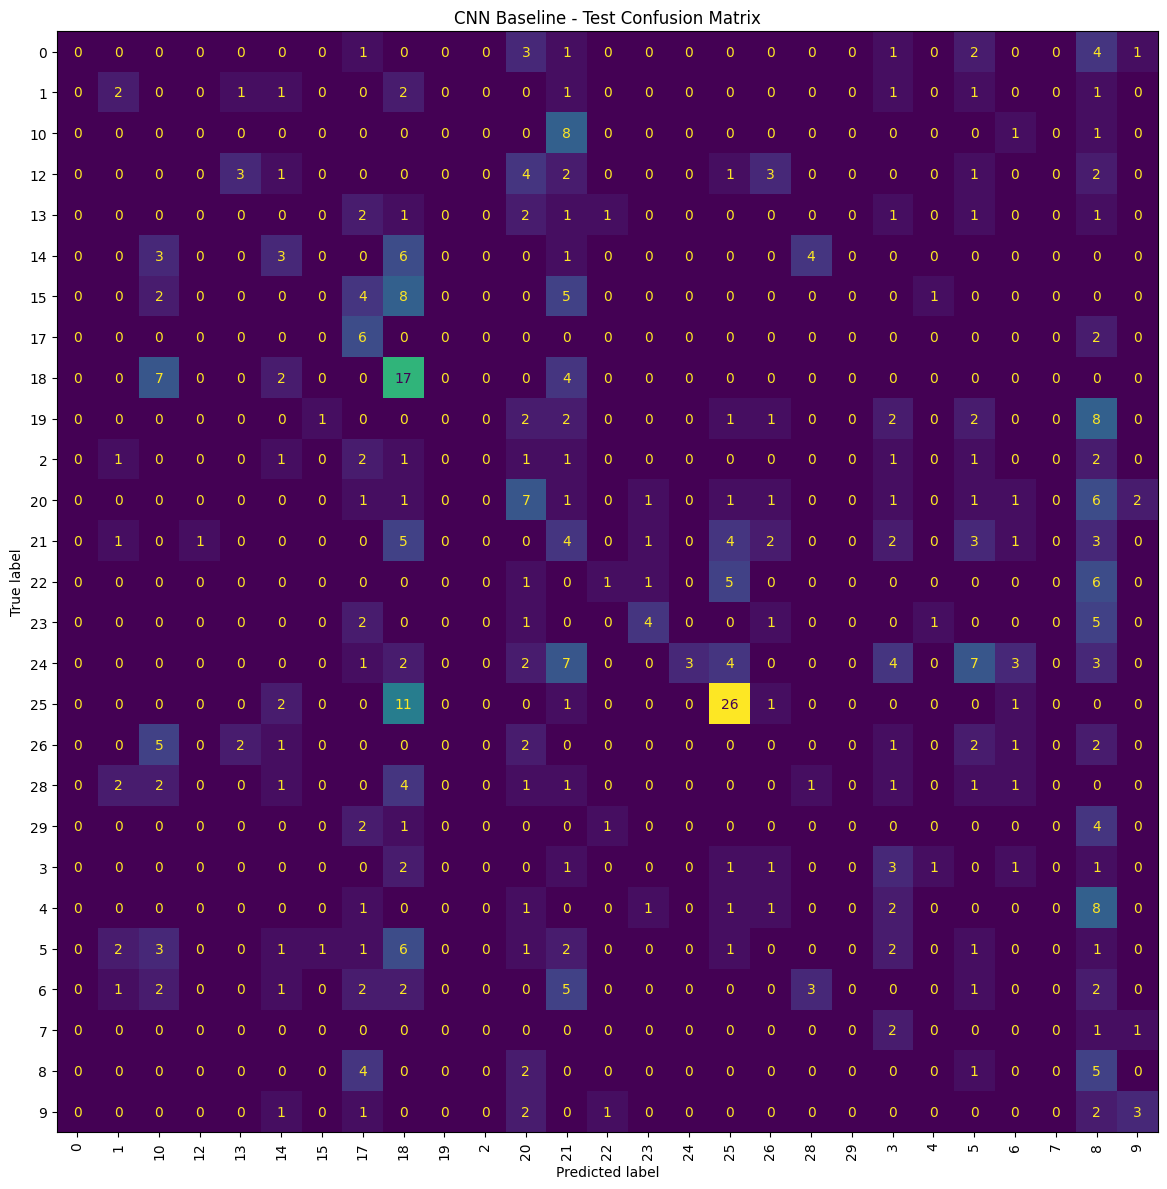

In [15]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best CNN checkpoint
cnn_model.load_state_dict(
    torch.load("/content/best_cnn_model.pth", map_location=device)
)
cnn_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test Accuracy: {test_accuracy:.4f}")

# Precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(test_dataset.classes))),
    target_names=test_dataset.classes,
    zero_division=0,
    digits=3
))

# Plot confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(test_dataset.classes)))
)

fig, ax = plt.subplots(figsize=(14, 12))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)
display.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
plt.title("CNN Baseline - Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Build the Vision Transformer (ViT)

In [16]:
import torch
import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

# Load pretrained Vision Transformer
vit_model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

# Replace the final layer for our 27 classes
num_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(
    num_features,
    len(train_dataset.classes)
)

# Move model to GPU
vit_model = vit_model.to(device)

# Loss function and optimizer
vit_criterion = nn.CrossEntropyLoss()
vit_optimizer = torch.optim.AdamW(
    vit_model.parameters(),
    lr=0.0001,
    weight_decay=0.01
)

print("Vision Transformer created successfully.")
print("Device:", device)
print("Number of classes:", len(train_dataset.classes))
print(
    "Trainable parameters:",
    sum(p.numel() for p in vit_model.parameters() if p.requires_grad)
)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 173MB/s]


Vision Transformer created successfully.
Device: cuda
Number of classes: 27
Trainable parameters: 85819419


#Train the Vision Transformer

In [17]:
import time
import torch

num_epochs = 5
best_vit_val_accuracy = 0.0
vit_history = []

for epoch in range(num_epochs):
    start_time = time.time()

    # Training phase
    vit_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        vit_optimizer.zero_grad()
        outputs = vit_model(images)
        loss = vit_criterion(outputs, labels)
        loss.backward()
        vit_optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation phase
    vit_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = vit_model(images)
            loss = vit_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    vit_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_accuracy > best_vit_val_accuracy:
        best_vit_val_accuracy = val_accuracy
        torch.save(vit_model.state_dict(), "/content/best_vit_model.pth")

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {time.time() - start_time:.1f}s"
    )

print(f"\nBest ViT validation accuracy: {best_vit_val_accuracy:.4f}")
print("Best model saved to /content/best_vit_model.pth")

Epoch [1/5] Train Loss: 1.6141 | Train Acc: 0.5273 | Val Loss: 1.3514 | Val Acc: 0.5968 | Time: 255.8s
Epoch [2/5] Train Loss: 0.7507 | Train Acc: 0.7637 | Val Loss: 1.3397 | Val Acc: 0.6153 | Time: 255.0s
Epoch [3/5] Train Loss: 0.4254 | Train Acc: 0.8645 | Val Loss: 1.3304 | Val Acc: 0.5984 | Time: 254.5s
Epoch [4/5] Train Loss: 0.2808 | Train Acc: 0.9175 | Val Loss: 1.5883 | Val Acc: 0.5888 | Time: 254.4s
Epoch [5/5] Train Loss: 0.2000 | Train Acc: 0.9382 | Val Loss: 1.4770 | Val Acc: 0.5952 | Time: 254.2s

Best ViT validation accuracy: 0.6153
Best model saved to /content/best_vit_model.pth
